In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, run_psy
from MLE_Predictive_Density import neg_loglik_student_mar, neg_loglik_student_marx, mar_studentt_pred_density, marx_studentt_pred_density


In [2]:
# Create Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility 
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import target series and detrend series with HP filter + linear trend of the volatility scaling

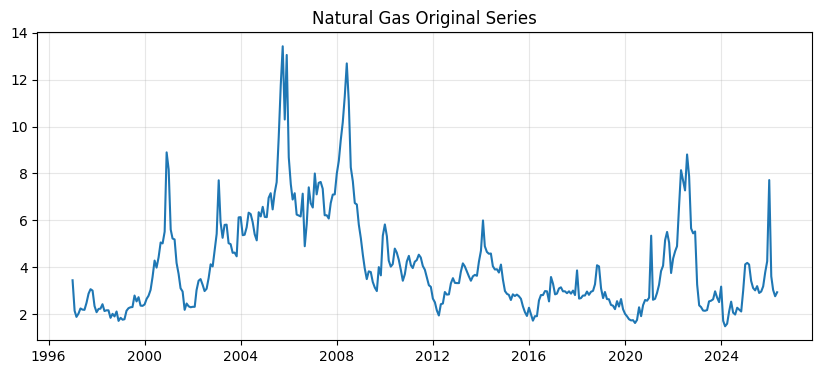

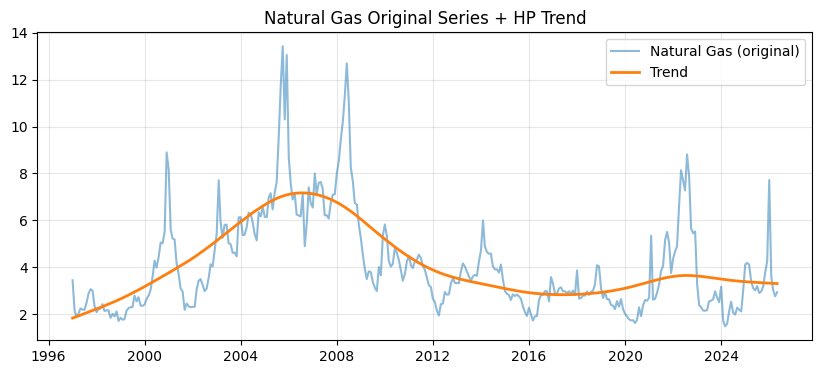

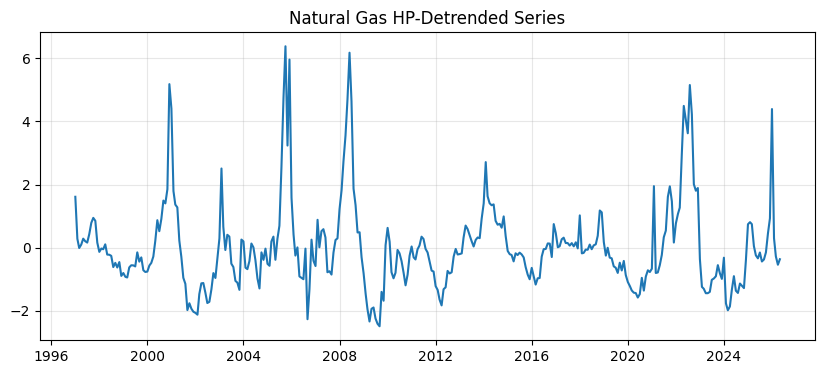

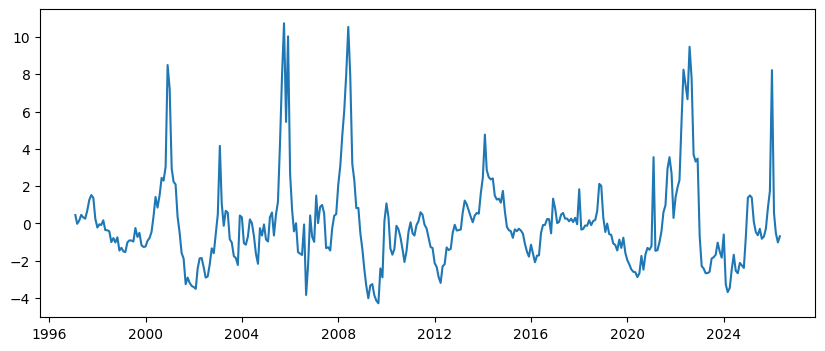

In [3]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend

# scaling by linear trend of the volatility
gas_diff = (df_ngas["gas_cycle"]).diff().dropna()
gas_sigma = linear_vol_scale(gas_diff)


df_ngas["gas_scaled_cycle"]= df_ngas["gas_cycle"]/gas_sigma

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
plt.title("Natural Gas Original Series")
plt.grid(alpha=0.3)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot original cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
plt.title("Natural Gas HP-Detrended Series")
plt.grid(True, alpha=0.3)
plt.show()

# Plot scaled cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_scaled_cycle"])
#plt.ylabel("HP-detrended price scaled \n by the linear trend \n of the volatility", fontsize=18)
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()


In [4]:
# Get PSY For Natural Gas and save as pickle

T = len(df_ngas)
r0 = 0.01 + 1.8 / np.sqrt(T)
swindow0 = int(np.floor(r0 * T))
yr = 2
Tb = 12 * yr + swindow0 - 1

psy = run_psy(
    y=df_ngas["MHHNGSP"].values,
    dates=df_ngas.index,
    IC=2,
    adflag=6,
    Tb = Tb,
    nboot=1999)


with open("psy_ngas.pkl", "wb") as f:
    pickle.dump(psy, f)

### Extract and Transform Data for Exogeous Variables

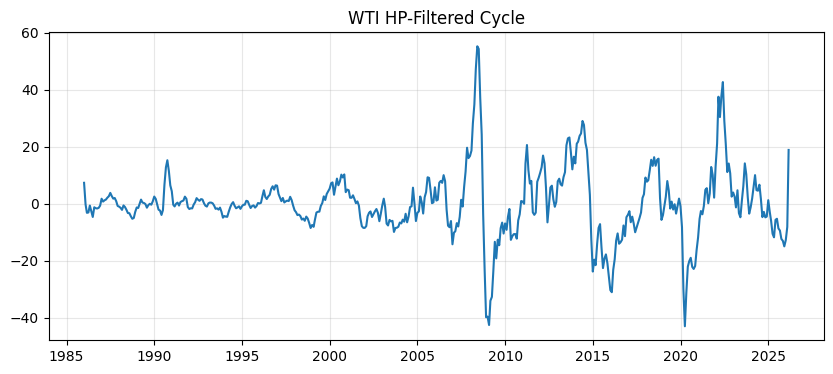

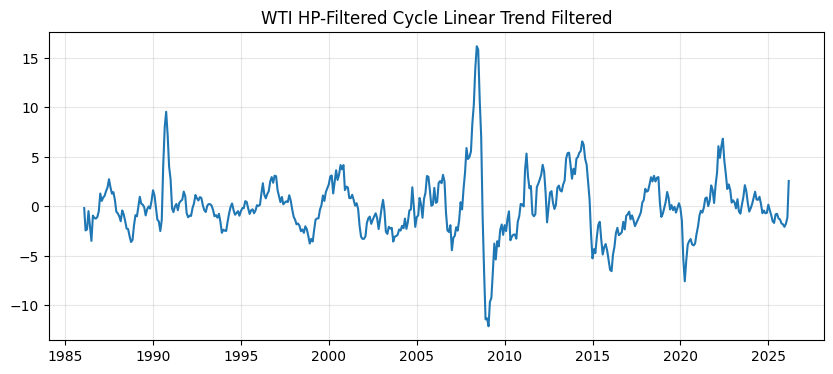

In [5]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
wti_cycle, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

wti_diff = (wti_cycle).diff().dropna()
wti_sigma = linear_vol_scale(wti_diff)

wti = wti_cycle/wti_sigma


plt.figure(figsize=(10,4))
plt.plot(wti_cycle)
plt.title("WTI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(wti)
plt.title("WTI HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_16237/2098523232.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


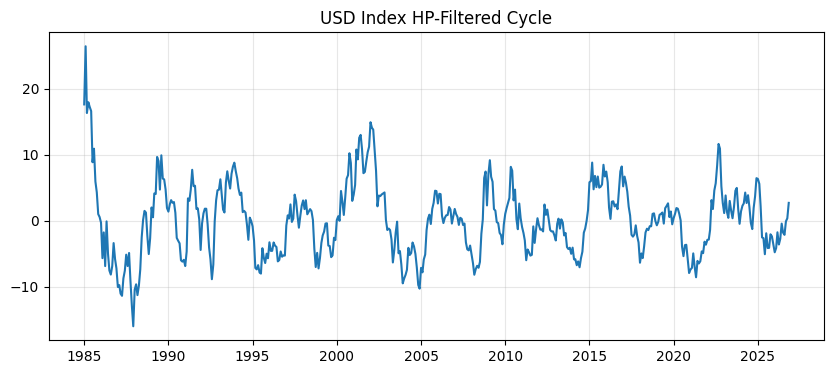

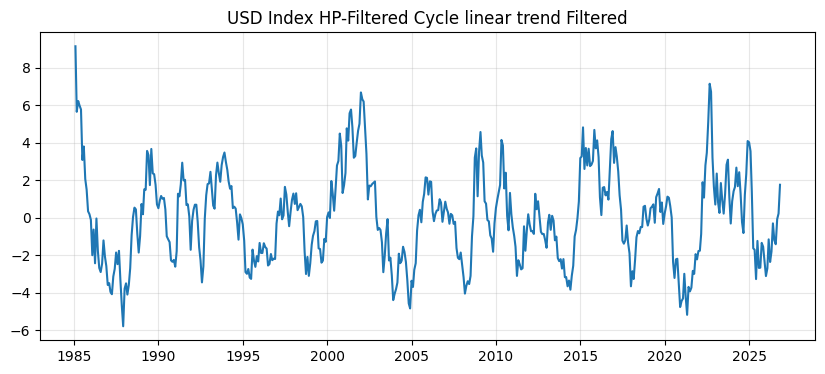

In [6]:
# -------------------------
# USD INDEX
# -------------------------
usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
usd_ind_original = usd_ind_original.dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
usd_ind_cycle, trend = hpfilter(usd_ind_original, lamb=129600)

usd_ind_diff = (usd_ind_cycle).diff().dropna()
usd_ind_sigma = linear_vol_scale(usd_ind_diff)

usd_ind= usd_ind_cycle/usd_ind_sigma


plt.figure(figsize=(10,4))
plt.plot(usd_ind_cycle)
plt.title("USD Index HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("USD Index HP-Filtered Cycle linear trend Filtered")
plt.grid(alpha=0.3)
plt.show()

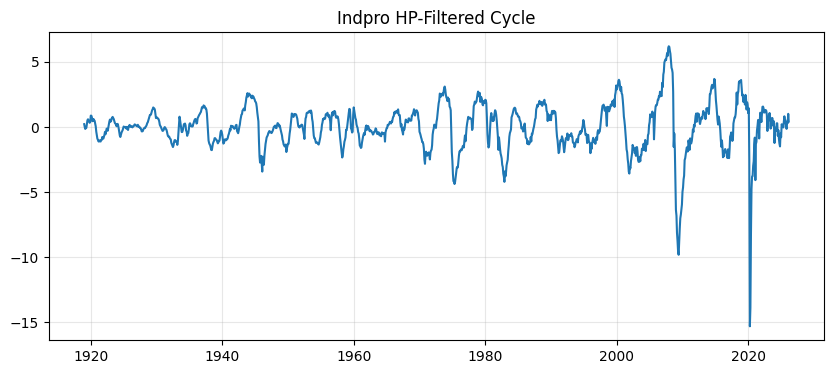

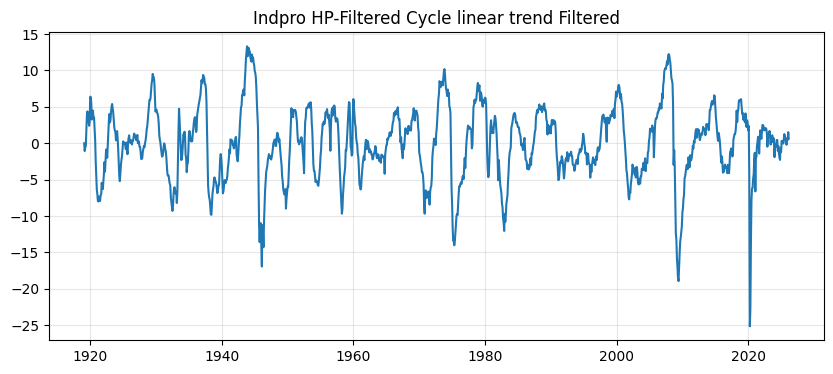

In [7]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle linear trend Filtered")
plt.grid(alpha=0.3)
plt.show()

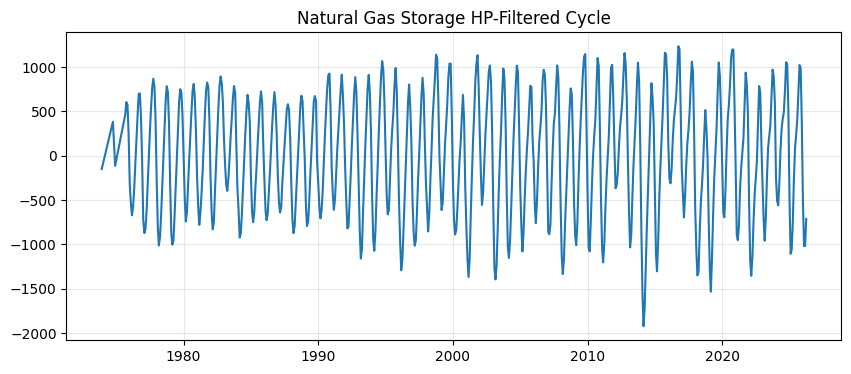

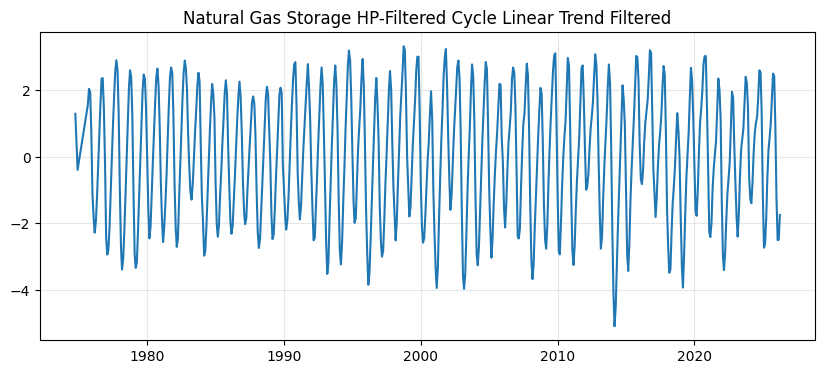

In [8]:
# -------------------------
# Natural Gas Storage
# -------------------------

df_ngas_storage = pd.read_excel(
    "Natural Gas Storage.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_storage["Date"] = pd.to_datetime(
    df_ngas_storage["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_storage["Date"] = df_ngas_storage["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_storage = df_ngas_storage.set_index("Date").dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------

df_ngas_storage=0.001*df_ngas_storage
ngas_storage_cycle, trend = hpfilter(
    df_ngas_storage["U.S. Natural Gas Underground Storage Volume (MMcf)"],
    lamb=129600
)

ngas_storage_diff = (ngas_storage_cycle).diff().dropna()
ngas_storage_sigma = linear_vol_scale(ngas_storage_diff)

ngas_storage = ngas_storage_cycle/ngas_storage_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_storage_cycle)
plt.title("Natural Gas Storage HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_storage)
plt.title("Natural Gas Storage HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

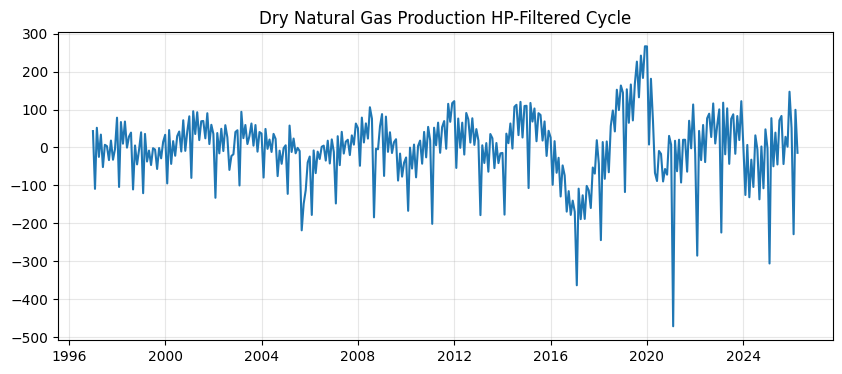

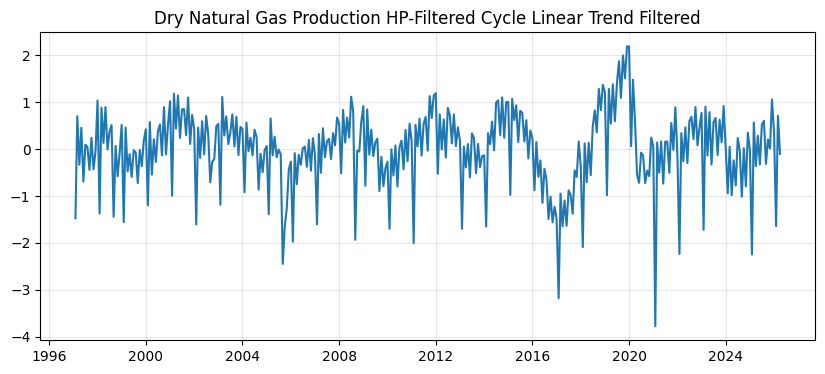

In [9]:
# -------------------------
# Dry Natural Gas Production
# -------------------------

df_ngas_prod = pd.read_excel(
    "Dry NGas Production.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_prod["Date"] = pd.to_datetime(
    df_ngas_prod["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_prod["Date"] = df_ngas_prod["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_prod = df_ngas_prod.set_index("Date").dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
df_ngas_prod=0.001*df_ngas_prod
ngas_prod_cycle, trend = hpfilter(
    df_ngas_prod["U.S. Dry Natural Gas Production (MMcf)"],
    lamb=129600
)


ngas_prod_diff = (ngas_prod_cycle).diff().dropna()
ngas_prod_sigma = linear_vol_scale(ngas_prod_diff)

ngas_prod = ngas_prod_cycle/ngas_prod_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_prod_cycle)
plt.title("Dry Natural Gas Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_prod)
plt.title("Dry Natural Gas Production HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

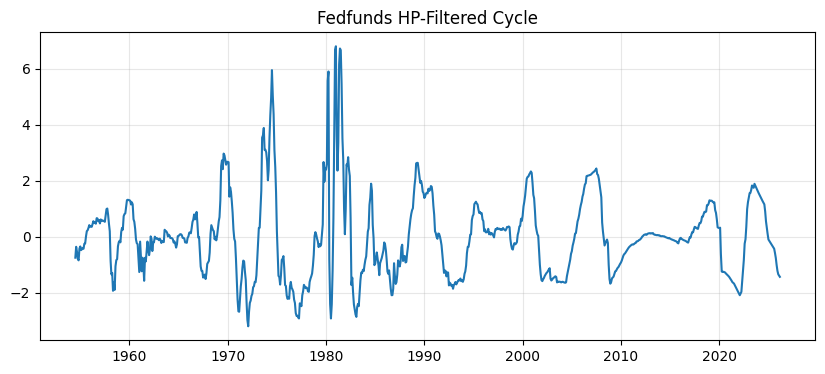

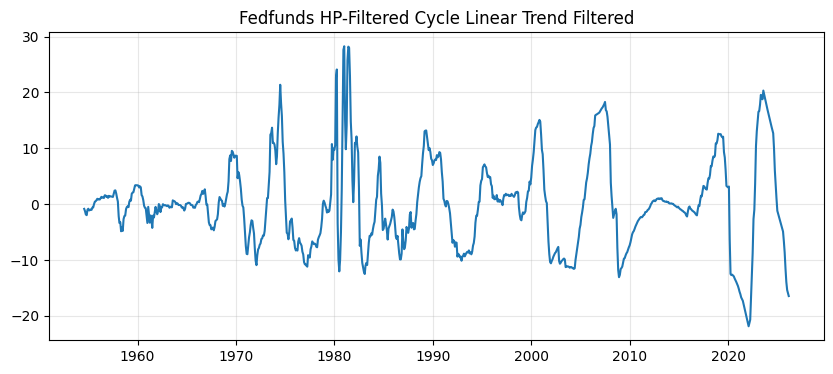

In [10]:
# -------------------------
# Fed Funds
# -------------------------
fedfunds_original = pd.read_csv("FEDFUNDS.csv", parse_dates=["observation_date"])
fedfunds_original = fedfunds_original.dropna().set_index("observation_date")

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
fedfunds_cycle, trend = hpfilter(fedfunds_original, lamb=129600)


fedfunds_diff = (fedfunds_cycle).diff().dropna()
fedfunds_sigma = linear_vol_scale(fedfunds_diff)

fedfunds = fedfunds_cycle/fedfunds_sigma


plt.figure(figsize=(10,4))
plt.plot(fedfunds_cycle)
plt.title("Fedfunds HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(fedfunds)
plt.title("Fedfunds HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_16237/1916681627.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


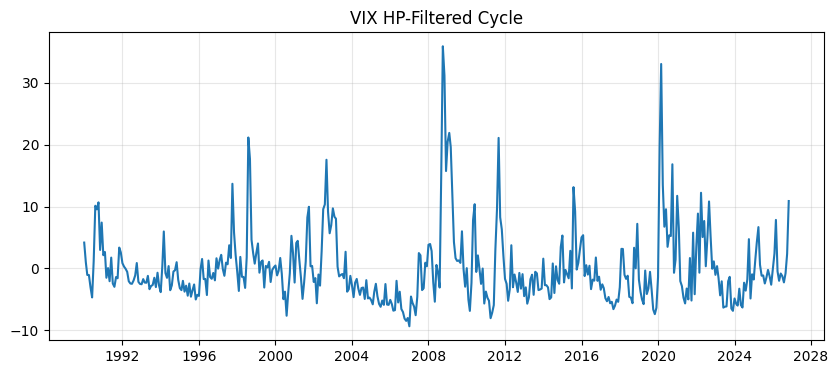

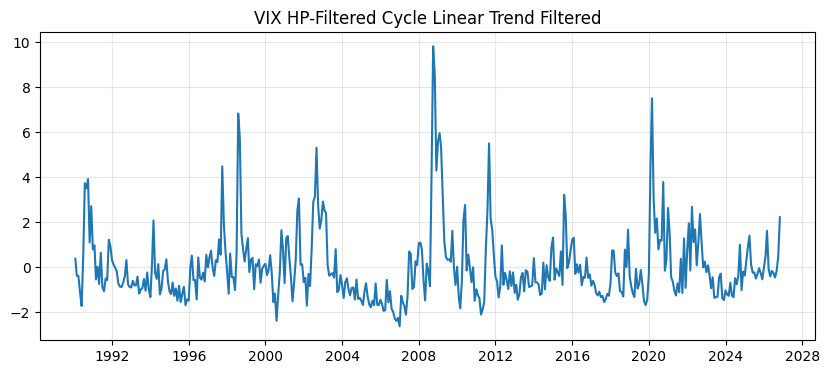

In [11]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma = linear_vol_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

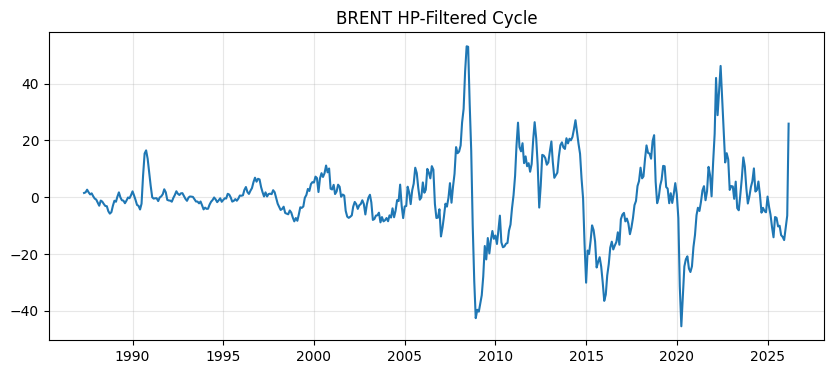

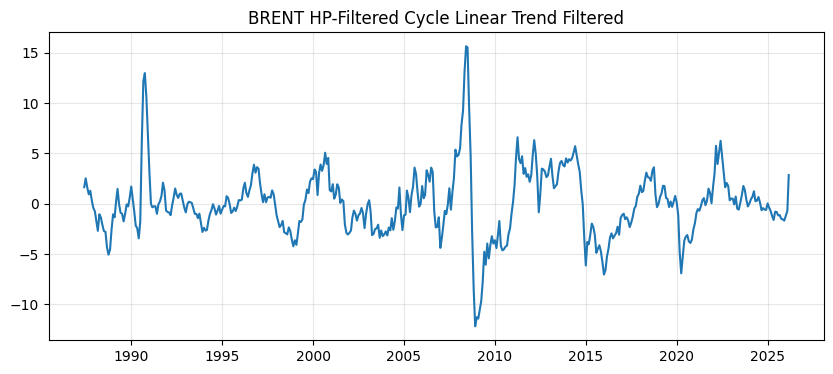

In [12]:
# -------------------------
# BRENT DATA
# -------------------------
df_brent = pd.read_csv("MCOILBRENTEU.csv", parse_dates=["observation_date"])
df_brent = df_brent.dropna().set_index("observation_date")

# HP filter + linear trend of the volatility scaling
brent_cycle, brent_trend = hpfilter(df_brent["MCOILBRENTEU"], lamb=129600)

brent_diff = (brent_cycle).diff().dropna()
brent_sigma = linear_vol_scale(brent_diff)

brent= brent_cycle/brent_sigma


plt.figure(figsize=(10,4))
plt.plot(brent_cycle)
plt.title("BRENT HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(brent)
plt.title("BRENT HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

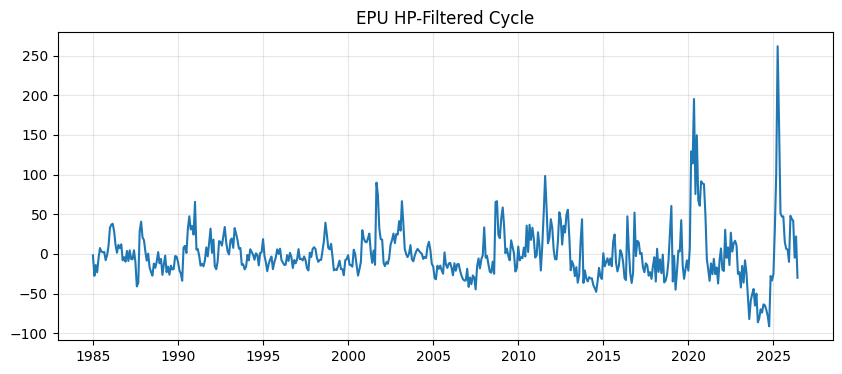

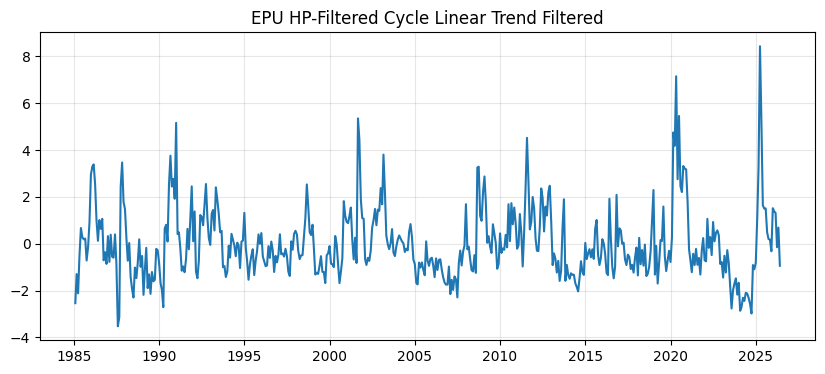

In [13]:
# -------------------------
# Economic Policy Uncertainty US
# -------------------------
df_epu = pd.read_csv("USEPUINDXM.csv", parse_dates=["observation_date"])
df_epu = df_epu.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
epu_cycle , trend = hpfilter(df_epu["USEPUINDXM"], lamb=129600)

epu_diff = (epu_cycle).diff().dropna()
epu_sigma = linear_vol_scale(epu_diff)

epu= epu_cycle/epu_sigma


plt.figure(figsize=(10,4))
plt.plot(epu_cycle)
plt.title("EPU HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(epu)
plt.title("EPU HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

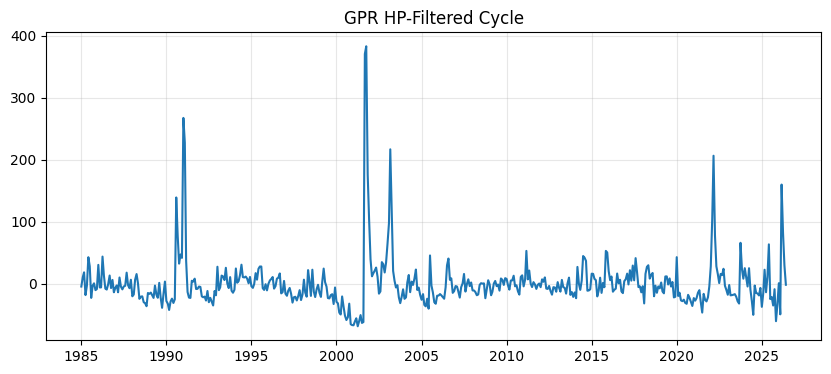

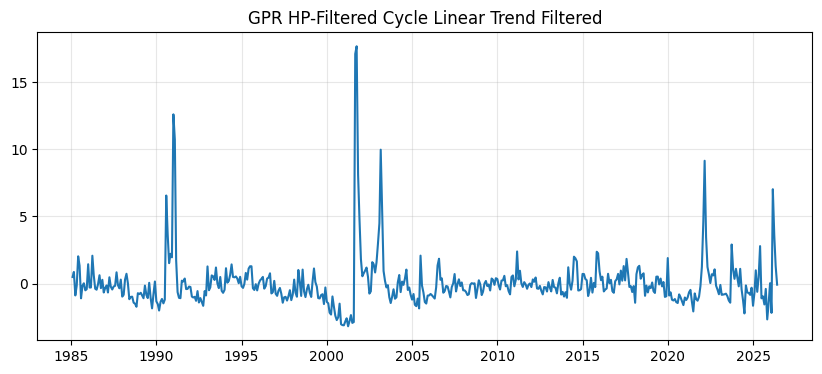

In [14]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
gpr_cycle, gpr_trend = hpfilter(gpr_original, lamb=129600)

gpr_diff = (gpr_cycle).diff().dropna()
gpr_sigma = linear_vol_scale(gpr_diff)

gpr = gpr_cycle/gpr_sigma


plt.figure(figsize=(10,4))
plt.plot(gpr_cycle)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_16237/4224487684.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


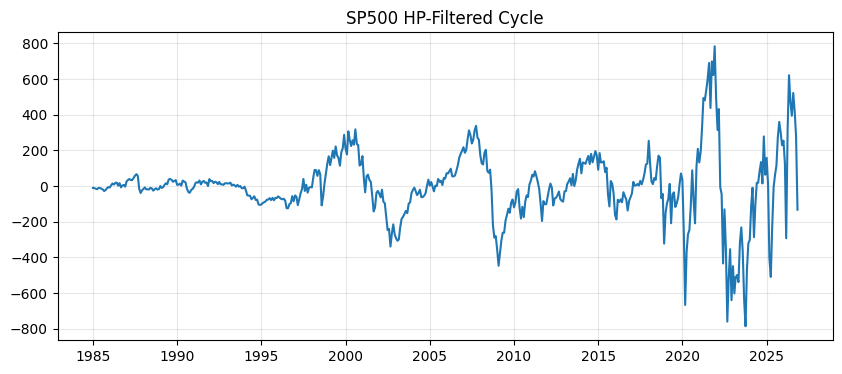

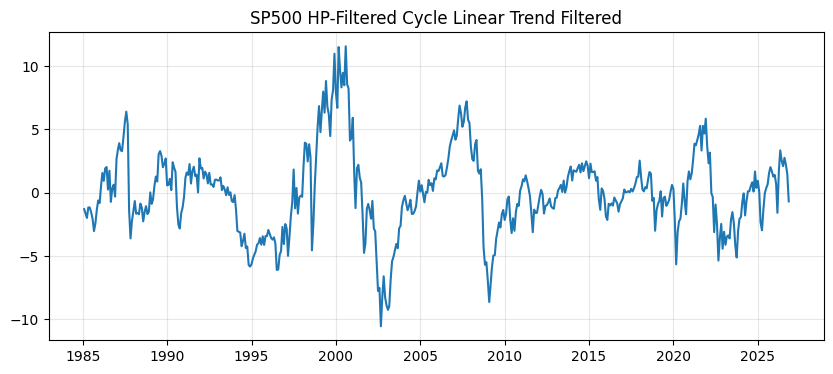

In [15]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter + linear trend of the volatility scaling
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

In [16]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_scaled_cycle"], wti, usd_ind, indpro, ngas_storage, ngas_prod, fedfunds, vix, brent, epu, gpr, sp500
    ],
    axis=1
).dropna()

df.columns = ["gas_scaled_cycle",  "wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "sp500"]
df = df.sort_index()


start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()


y = df["gas_scaled_cycle"].values
X = df[["wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "sp500"]].values

var = ["wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr",  "sp500"]

t0=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=3000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)

prominence = 0.01
y_limits=(-10, 15)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -489.1380261790016

Estimated parameters:
phi             =     0.2290 (0.0334)
psi             =     0.7936 (0.0235)
sigma           =     0.5206 (0.0411)
nu              =     1.7051 (0.2141)

Hessian condition number:
102.32349904452732

Eigenvalues of Hessian:
[2201.93218113  828.49849474  948.53094555   21.5193206 ]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -489.138026
AIC:            986.276052
BIC:            1001.684862
R^2:            0.685313

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 12.878816, p-value = 0.000332322
    lag  5: statistic = 25.582401, p-value = 0.000107512
    lag 10: statistic = 36.091014, p-value = 8.11976e-05
    lag 20: statistic = 41.415793, p-value = 0.00329303

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: s

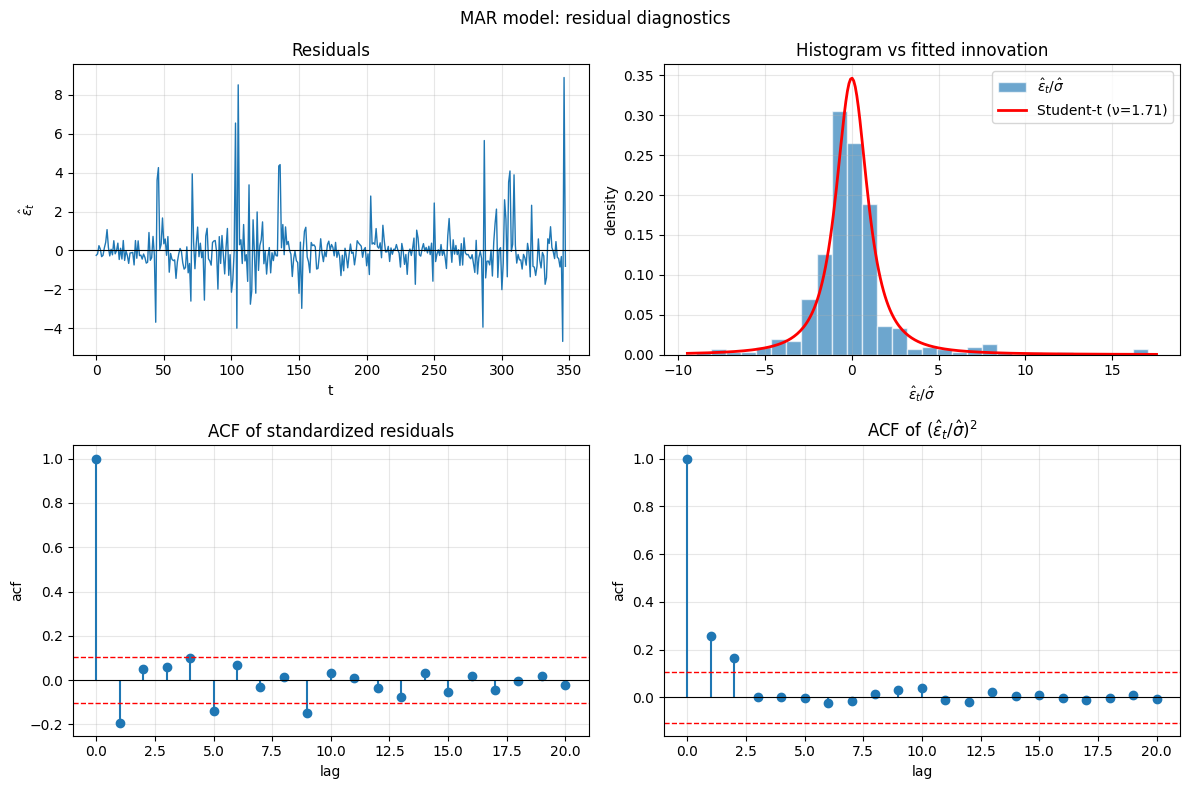

In [17]:
param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

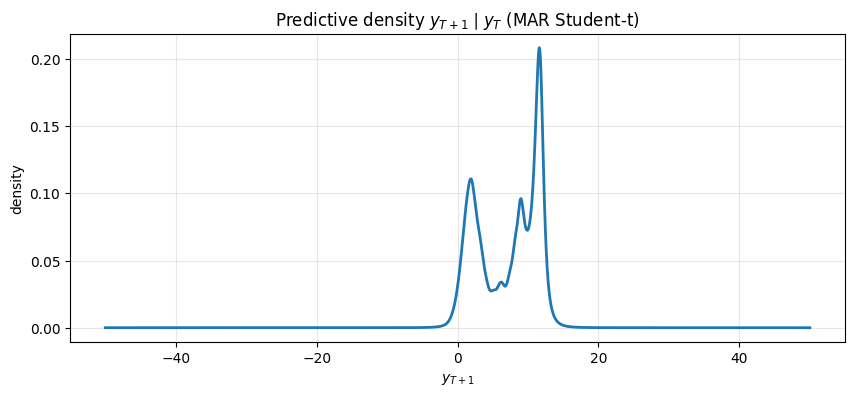

In [18]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

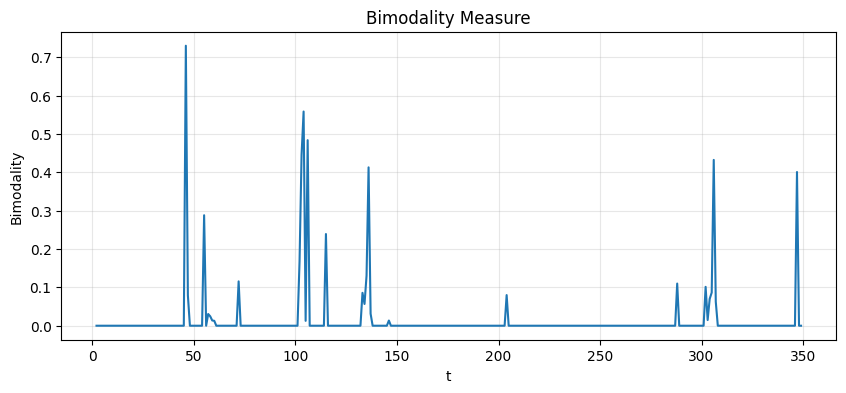

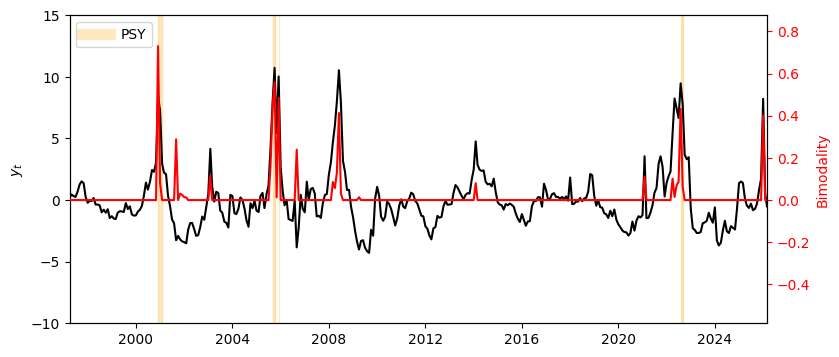

In [19]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -479.47329716197873

Estimated parameters:
phi             =     0.7750 (0.0425)
psi             =     0.1282 (0.0464)
beta_wti        =     0.0819 (0.0532)
beta_usd_ind    =     0.0302 (0.0200)
beta_indpro     =     0.0336 (0.0160)
beta_ngas_storage =    -0.0059 (0.0203)
beta_ngas_prod  =    -0.0922 (0.0545)
beta_fedfunds   =    -0.0248 (0.0070)
beta_vix        =    -0.0000 (0.0303)
beta_brent      =     0.0049 (0.0479)
beta_epu        =    -0.0255 (0.0324)
beta_gpr        =    -0.0666 (0.0254)
beta_sp500      =    -0.0025 (0.0179)
sigma           =     0.5339 (0.0422)
nu              =     1.8525 (0.2484)

Hessian condition number:
4202.202751311773

Eigenvalues of Hessian:
[6.69908830e+04 2.08035752e+04 8.22148523e+03 3.96381692e+03
 3.36843376e+03 2.39694810e+03 1.87448629e+03 1.57596493e+03
 1.59418493e+01 1.95297446e+02 2.67901754e+02 4.41081571e+02
 1.07780886e+03 7.10863920e+02 9.42458626e+02]

MLE diagnostics

--- MARX model diagnosti

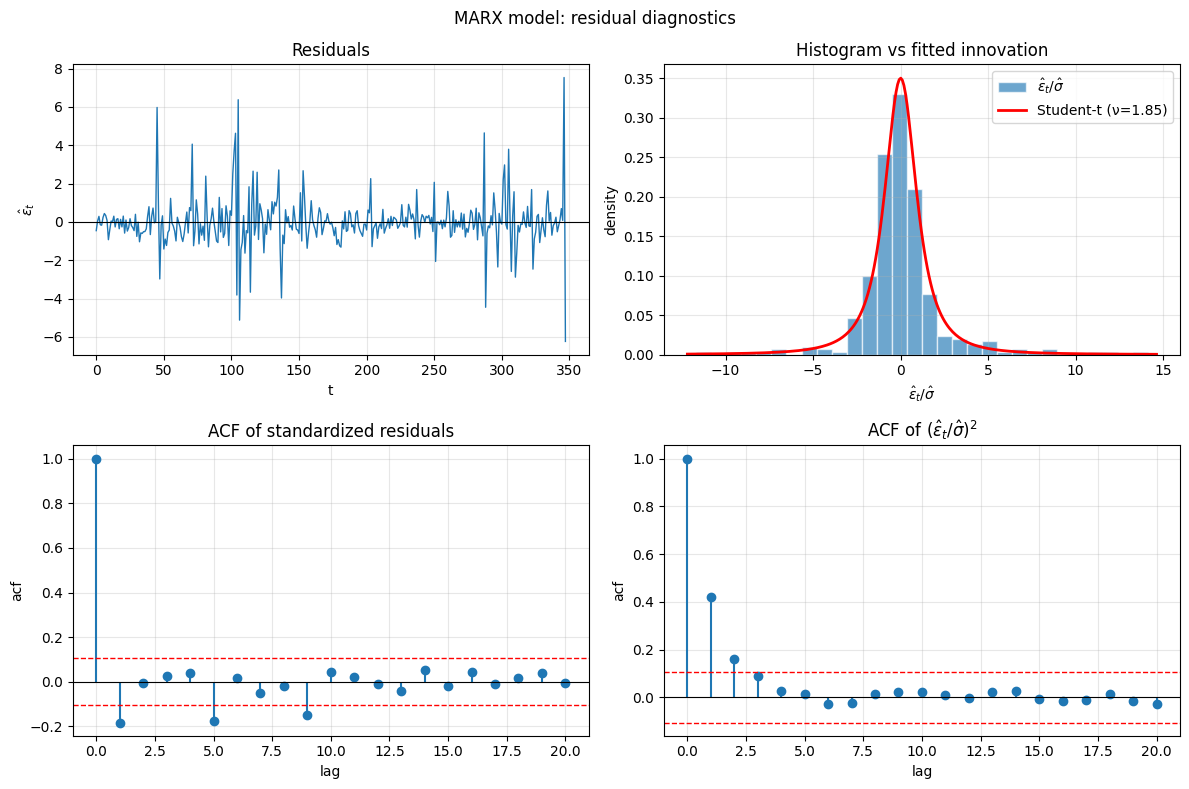

In [20]:
param_names = [ "phi", "psi", "beta_wti", "beta_usd_ind", "beta_indpro", "beta_ngas_storage", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_brent", "beta_epu", "beta_gpr", "beta_sp500", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### BIC Selection for Exogenous Regressors

In [21]:

from marx_bic_exhaustive import exhaustive_bic_marx

selection = exhaustive_bic_marx(
    y=y,
    X=X,
    names=var,
    n_starts=5,
    seed=42,
    min_nu=0.1,
    checkpoint="ngas_bic_checkpoint.pkl",
    save_every=25
)

display(selection["table"].head(20))


from marx_bic_exhaustive import refit_top_subsets

selection = refit_top_subsets(
    selection,
    y=y,
    X=X,
    names=var,
    top_n=10,
    n_starts=40
)

display(selection["table"].head(10))

best = selection["best"]

print("Selected regressors:", selection["selected_names"])
print("Log-likelihood:", best["loglik"])
print("AIC:", best["AIC"])
print("BIC:", best["BIC"])
print("Estimated nu:", best["theta"][-1])
print("Estimated parameters:", best["theta"])

New fits: 500 | recorded 500/2048
New fits: 1000 | recorded 1000/2048
New fits: 1500 | recorded 1500/2048
New fits: 2000 | recorded 2000/2048
Finished: 2048/2048 subsets; successes=2048, failures=0
Best subset: []
Best BIC=1001.684862; nu=1.7051


,regressors,ids,n_regressors,success,loglik,AIC,BIC,nu,n_converged
0,(none),(),0,True,-489.138026,986.276052,1001.684862,1.705144,5
1,wti,"(0,)",1,True,-488.319511,986.639022,1005.900035,1.762780,5
2,indpro,"(2,)",1,True,-488.323066,986.646131,1005.907144,1.731186,5
3,gpr,"(9,)",1,True,-488.537554,987.075107,1006.336120,1.732832,5
4,brent,"(7,)",1,True,-488.749836,987.499671,1006.760684,1.737765,5
5,sp500,"(10,)",1,True,-488.788677,987.577354,1006.838366,1.674927,5
6,ngas_storage,"(3,)",1,True,-488.874420,987.748839,1007.009852,1.722660,5
7,vix,"(6,)",1,True,-489.082352,988.164705,1007.425717,1.706006,5
8,ngas_prod,"(4,)",1,True,-489.120625,988.241250,1007.502263,1.704425,5
9,usd_ind,"(1,)",1,True,-489.134508,988.269015,1007.530027,1.704777,5


,regressors,ids,n_regressors,success,loglik,AIC,BIC,nu,n_converged
0,(none),(),0,True,-489.138026,986.276052,1001.684862,1.705144,5
1,wti,"(0,)",1,True,-488.319511,986.639022,1005.900035,1.762780,40
2,indpro,"(2,)",1,True,-488.323066,986.646131,1005.907144,1.731186,40
3,gpr,"(9,)",1,True,-488.537554,987.075107,1006.336120,1.732832,40
4,brent,"(7,)",1,True,-488.749836,987.499671,1006.760684,1.737764,40
5,sp500,"(10,)",1,True,-488.788677,987.577354,1006.838366,1.674926,40
6,ngas_storage,"(3,)",1,True,-488.874420,987.748839,1007.009852,1.722660,40
7,vix,"(6,)",1,True,-489.082352,988.164705,1007.425717,1.706006,40
8,ngas_prod,"(4,)",1,True,-489.120625,988.241250,1007.502263,1.704425,40
9,usd_ind,"(1,)",1,True,-489.134508,988.269015,1007.530027,1.704777,5


Selected regressors: []
Log-likelihood: -489.1380261790017
AIC: 986.2760523580034
BIC: 1001.6848622771013
Estimated nu: 1.7051444308746737
Estimated parameters: [0.22899649 0.79363343 0.52061685 1.70514443]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

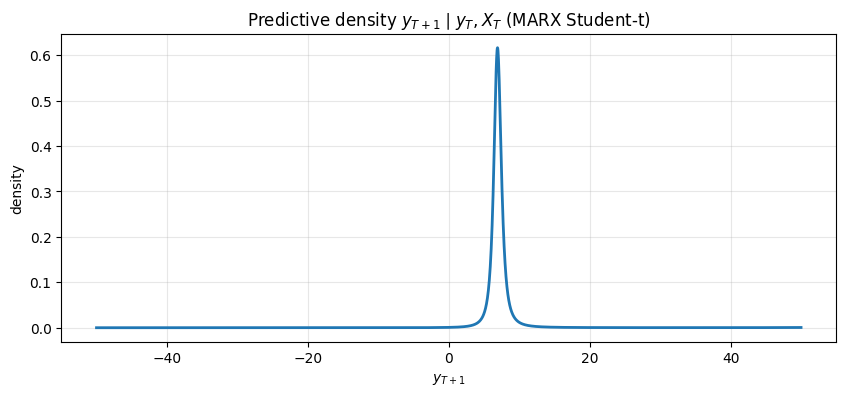

In [22]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

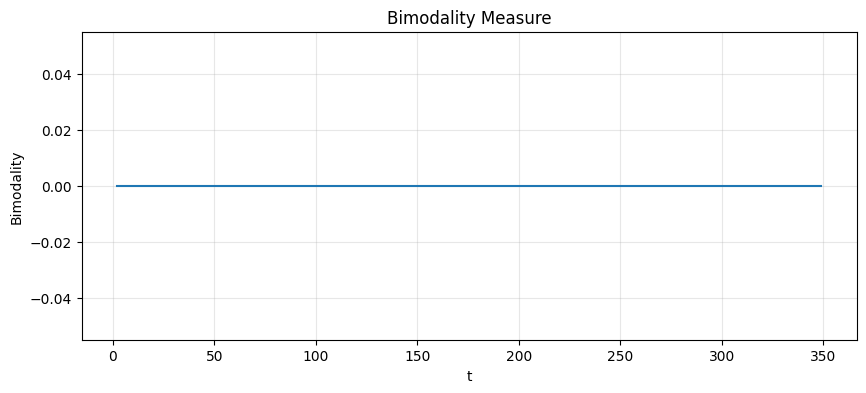

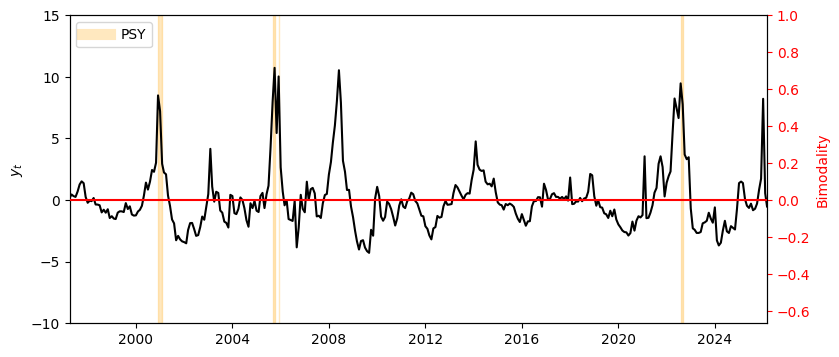

In [23]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)
